# DATA CHALLENGE 2
#### PROJET 1 :  prédiction de survenue (oui ou non) d'exacerbations de l'asthme, pour chaque patient, dans l'année suivant le début du traitement.
#### Groupe 6 :
- Mehdi MEHNANE​
- Cornelius NKRUMAH-BUADII
- Abdo MIRGAN​

Notre objectif est de construire un *pipeline* de *machine learning* qui pourra fonctionner sur un fichier de même structure que le fichier de données initial ("trainDataDC2.csv.gz" ci-dessus) et qui nous donnera, en sortie, la prédiction de survenue (oui ou non) d'exacerbations de l'asthme, pour chaque patient, dans l'année suivant le début du traitement.

## 1. Importation des données

In [ ]:
import pathlib

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from imblearn.ensemble import BalancedBaggingClassifier

#Unbalanced 
from imblearn.pipeline import Pipeline
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_val_predict,
    learning_curve,
    train_test_split,
)

# Preprocessing 
from sklearn.preprocessing import (
    FunctionTransformer,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.utils import estimator_html_repr
from skopt import BayesSearchCV
from skopt.callbacks import DeltaYStopper
from skopt.space import Integer, Real

- [Polars](https://docs.pola.rs)
- [Sklearn](https://scikit-learn.org/stable/api/sklearn.html#)

In [2]:
pl.Config.set_tbl_cols(-1) # afficher toute les colonnes 
pl.Config.set_tbl_rows(-1) # afficher toute les lignes

polars.config.Config

In [3]:
data="trainDataDC2.csv.gz"
df=pl.read_csv(data)
df.shape

(14575, 21)

In [4]:
df.head()

patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
i64,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
1073754155,"""14""","""1""","""1""",0,"""0""","""0""","""1""","""0""","""1""","""0""","""0""","""NA""","""1224.7674731""","""1""","""314""","""218.13""","""0""","""NA""","""7.1105062871""","""5.3850912153"""
1073799394,"""NA""","""1""","""2""",2,"""0""","""1""","""1""","""0""","""0""","""0""","""1""","""NA""","""20290.534269""","""0""","""NA""","""44.98""","""0""","""0""","""9.9179097641""","""3.8062179465"""
1073854918,"""62""","""1""","""NA""",0,"""0""","""0""","""NA""","""0""","""0""","""0""","""0""","""0.7384196185""","""2964.2541751""","""NA""","""480""","""99.26""","""0""","""0""","""7.9943807368""","""4.5977426702"""
1073898249,"""NA""","""1""","""2""",0,"""0""","""0""","""1""","""0""","""1""","""NA""","""0""","""0.0844686649""","""3223.7088196""","""0""","""0""","""59.58""","""0""","""1""","""8.0782877831""","""NA"""
1073913003,"""40""","""1""","""1""",0,"""0""","""1""","""0""","""1""","""1""","""0""","""1""","""0.5068119891""","""1287.2543683""","""2""","""689""","""NA""","""0""","""0""","""7.1602668324""","""3.3941727667"""


In [5]:
df.schema

Schema([('patid', Int64),
        ('index_age', String),
        ('previous_asthma_drugs', String),
        ('total_pre_index_cannisters_365', String),
        ('post_index_exacerbations365', Int64),
        ('pneumonia', String),
        ('sinusitis', String),
        ('acute_bronchitis', String),
        ('acute_laryngitis', String),
        ('upper_respiratory_infection', String),
        ('gerd', String),
        ('rhinitis', String),
        ('adherence', String),
        ('total_pre_index_charge', String),
        ('pre_asthma_days', String),
        ('pre_asthma_charge', String),
        ('pre_asthma_pharma_charge', String),
        ('drug_s', String),
        ('female', String),
        ('log_charges', String),
        ('log_asthma_charge', String)])

## 2. Partitionner les données

#### Séparer les *features* ($X$) et l'*outcome* ($y$)

D'après le cahier de variables (fichier "DescriptionVariables.md"), la variable dépendante (que l'on veut prédire, *outcome*, *label*, *target*, notée $y$) est `post_index_exacerbations365`, à savoir le nombre d'exacerbations durant l'année suivant le début du traitement.
Toutes les autres variables sont a priori les caractéristiques (variables indépendantes, *features*, notées $X$) : excluons l'identifiant patient `patid` et les variables transformées `log_*`.

Dans ce projet il est lieu de prédire si y'aura exacerbations ou non (0 ou 1)

Attention au **Data leakage** = Une information issue du futur test influence l’entraînement.

Le modèle a accès, directement ou indirectement, à une information qu’il ne devrait pas connaître au moment de la prédiction

Pas de preprocessing avant split (imputation , encodage , calcul statistiques..., rééchantillonner l' ensemble des donnees)


***features***

In [6]:
features=df.select(pl.exclude("patid","post_index_exacerbations365"))

In [7]:
features.shape  

(14575, 19)

In [8]:
features.sample()

index_age,previous_asthma_drugs,total_pre_index_cannisters_365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""19""","""1""","""NA""","""0""","""0""","""0""","""NA""","""0""","""0""","""1""","""0.2534059946""","""4929.5842428""","""2""","""144""","""2050.32""","""0""","""1""","""8.5030099314""","""7.6257511575"""


***outcomes/classe/target/cibles***

In [9]:
df=df.with_columns(
        pl.when(pl.col("post_index_exacerbations365") > 0)
          .then(pl.lit(1))
          .otherwise(pl.lit(0))
          .alias("post_index_exacerbations365")
    )
target = df["post_index_exacerbations365"]

In [10]:
target.unique()

post_index_exacerbations365
i32
0
1


In [11]:
target.shape

(14575,)

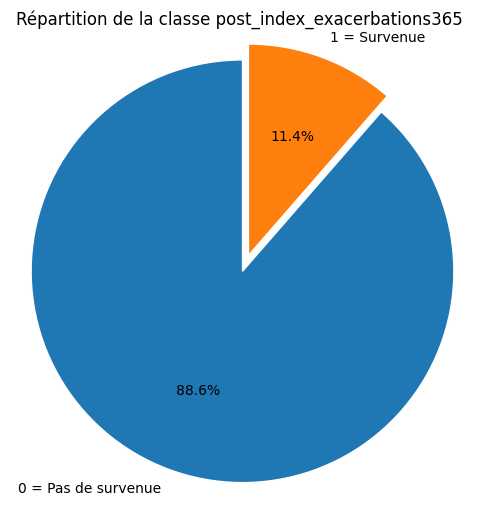

In [12]:
counts = target.value_counts().sort("post_index_exacerbations365")
labels = ["0 = Pas de survenue", "1 = Survenue"]
sizes = counts["count"].to_list()

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.02, 0.06),
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)
plt.title("Répartition de la classe post_index_exacerbations365 ")
plt.axis("equal")
plt.show()

***train tes split***

In [13]:
X_train,X_test,y_train,y_test=train_test_split(
    features,
    target,
    test_size=.2,
    shuffle=True,
    random_state=42,
    #stratify=target
)

X_train.shape,X_test.shape,y_train.shape,y_test.shape

((11660, 19), (2915, 19), (11660,), (2915,))

In [14]:
y_train.value_counts()

post_index_exacerbations365,count
i32,u32
1,1298
0,10362


## 3. Préprocessing 

In [15]:
type(X_train)

polars.dataframe.frame.DataFrame

In [16]:
for col, dtype in X_train.schema.items():
    if dtype == pl.String:
        uniques = df.select(pl.col(col).unique()).to_series().to_list()
        print(f"{col :-<30} {uniques}")


index_age--------------------- ['12', '55', '53', '16', '52', '27', '14', '25', '42', '48', '44', '24', '57', '50', '38', '23', '17', '61', '32', '43', '49', '46', '40', '39', '28', '31', '51', '54', '13', '64', '37', '33', '29', '35', '47', '20', '34', '60', '22', '62', '26', '59', 'NA', '41', '65', '36', '21', '19', '45', '15', '58', '63', '56', '30', '18']
previous_asthma_drugs--------- ['1', 'NA']
total_pre_index_cannisters_365 ['2', 'NA', '0', '1']
pneumonia--------------------- ['1', 'NA', '0']
sinusitis--------------------- ['1', 'NA', '0']
acute_bronchitis-------------- ['NA', '0', '1']
acute_laryngitis-------------- ['1', 'NA', '0']
upper_respiratory_infection--- ['1', '0', 'NA']
gerd-------------------------- ['0', '1', 'NA']
rhinitis---------------------- ['NA', '0', '1']
adherence--------------------- ['0.6730245232', '0.9237057221', '0.3569482289', '0.2861035422', '0.2207084469', '0.7111716621', '0.2534059946', '0.3678474114', '0.2942779292', '0.9209809264', '0.6021798365'

In [17]:
numeric_features_int = [
 'index_age',
 'total_pre_index_cannisters_365',
 'pre_asthma_days',
]
numeric_features_float = [
 'adherence',
 'total_pre_index_charge',
 'pre_asthma_pharma_charge',
 'pre_asthma_charge',
 'log_charges',
 'log_asthma_charge',
]

categorical_features = [
 'previous_asthma_drugs',
 'pneumonia',
 'sinusitis',
 'acute_bronchitis',
 'acute_laryngitis',
 'upper_respiratory_infection',
 'gerd',
 'rhinitis',
 'drug_s',
 'female',
]

*“La somme de mes catégories + entiers + floats doit être exactement égale au nombre total de colonnes.”*

In [18]:
'''assert (
    len(categorical_features) +
    len(numeric_features_int) +
    len(numeric_features_float) == len(features.columns)
)'''

'assert (\n    len(categorical_features) +\n    len(numeric_features_int) +\n    len(numeric_features_float) == len(features.columns)\n)'

***Fonction de conversion de type***

In [19]:
def cast_float(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(numeric_features_float)
          .replace("NA", None)
          .cast(pl.Float64, strict=False)
    )


def cast_int(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(numeric_features_int)
          .replace("NA", None)
          .cast(pl.Int64, strict=False)
    )

def cast_categ(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(categorical_features)
          .replace("NA", None)
          .cast(pl.Int8, strict=False) # si utf8 besoin d encodage sinon non

    )

[FunctionTransformer](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.FunctionTransformer.html)

In [20]:
# construct a data transformer from a user-defined function
# input columns → output columns (mêmes noms)
cast_int_transformer = FunctionTransformer(cast_int,feature_names_out="one-to-one")
cast_float_transformer = FunctionTransformer(cast_float,feature_names_out="one-to-one")
cast_categ_transformer = FunctionTransformer(cast_categ,feature_names_out="one-to-one")

***Pipeline***

- [Pipeline , columns transformer](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html#preprocessing)
- [Imputation](https://scikit-learn.org/stable/modules/impute.html)

***Pipeline int***

In [21]:
int_pipeline = Pipeline(
    steps=[
        ("cast int",cast_int_transformer),
        ("imputer int", SimpleImputer(strategy="median")), 
        #("scaler int ", RobustScaler())
        ]
)

In [22]:
int_pipeline

,steps,"[('cast int', ...), ('imputer int', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002420920E520>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Pipeline float***

In [23]:
float_pipeline = Pipeline(
    steps=[
        ("cast float",cast_float_transformer),
        ("imputer float", SimpleImputer(strategy="median")), 
        #("scaler", RobustScaler())
        ]
)

In [24]:
float_pipeline

,steps,"[('cast float', ...), ('imputer float', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002420920E3E0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Pipeline categ***

In [25]:
catogorical_pipeline = Pipeline(
    steps=[
        ("cast cat",cast_categ_transformer),
        ("imputer cat", SimpleImputer(strategy="most_frequent")), 
        #("encode", OneHotEncoder(handle_unknown="ignore")) #Les arbres : savent gérer des variables catégorielles encodées en 0/1
        ] 
)


In [26]:
catogorical_pipeline

,steps,"[('cast cat', ...), ('imputer cat', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002420920E480>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Column tranformer***

[Columns transformer](https://scikit-learn.org/stable/modules/compose.html#column-transformer)

Applique des transformateurs aux colonnes d'un tableau ou d'un DataFrame pandas/polars. Cette méthode est particulièrement utile pour les données hétérogènes ou colonnaires, car elle permet de combiner plusieurs mécanismes d'extraction ou de transformation de caractéristiques au sein d'un seul transformateur

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num_float', float_pipeline, numeric_features_float),
        ('num_int', int_pipeline, numeric_features_int),
        ('cat', catogorical_pipeline, categorical_features)
    ],
    #remainder="passthrough"
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_float', ...), ('num_int', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

## 4. : Construire un modele

***Bagging Modele***

- Un modèle sous-ajusté présente un biais élevé et une faible variance, tandis qu'un modèle sur-ajusté présente une variance élevée et un biais faible
- L'apprentissage d'ensembles (combiner +sieurs models ) vise à résoudre ce compromis biais-variance en réduisant soit le biais, soit la variance.
- **Bagging :** consistent à entraîner plusieurs modèles indépendamment et en parallèle sur différents sous-ensembles des données d'entraînement, puis à combiner leurs prédictions pour obtenir une prédiction finale.
Different de boosting (Entrainement sequentiel ,corrige les erreurs des précédents)
- Permet de créer un ensemble diversifié de modèles qui capturent différents aspects des données.
- Le bagging, également appelé **agrégation par bootstrap**, se compose de deux étapes : **l’amorçage et l’agrégation**.
- **Amorçage :** Des sous-échantillons bootstrap sont générés par rééchantillonnage avec remise à partir des données initiales afin d’entraîner plusieurs modèles faibles indépendants.
- **Agrégation :** Les prédictions de ces modèles sont ensuite combinées, généralement par vote majoritaire ou moyenne, pour produire une prédiction finale plus stable et robuste.
- **Le bagging réduit principalement la variance du modèle en stabilisant les prédictions.** 


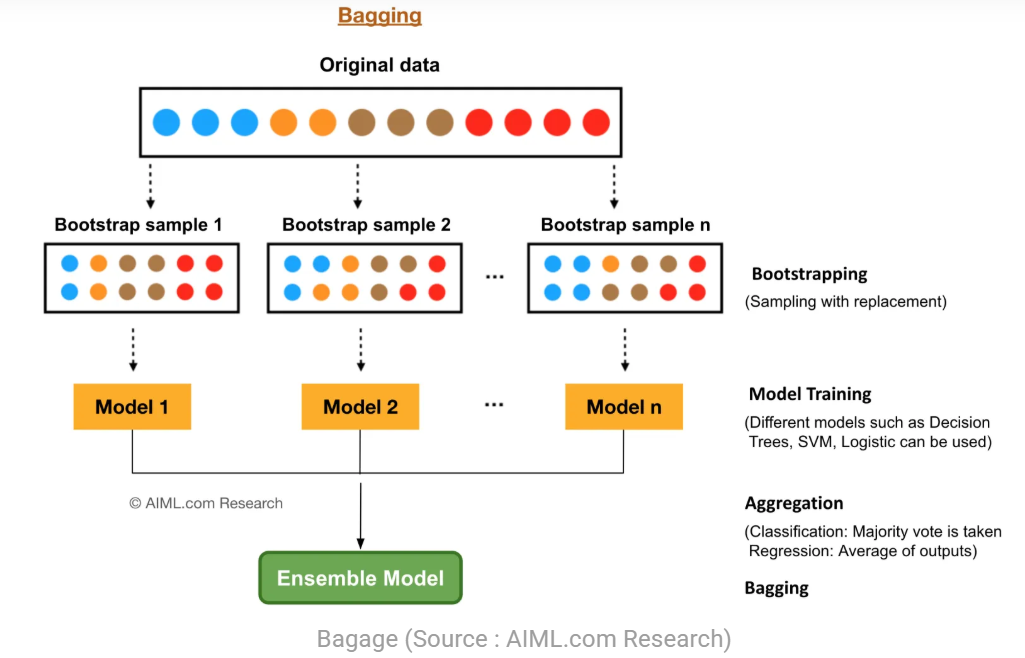

**Paramètres du classificateur Bagging :**


- n_estimators = Nombre d’arbres. ↑ → variance ↓, modèle plus stable, temps ↑.

- max_samples =  Nombre d’échantillons tirés de X pour entraîner chaque estimateur de base. Proportion d’observations par arbre.↓ → plus de diversité, variance ↓.

- max_features = Nombre de caractéristiques tirées de X pour entraîner chaque estimateur de base. Proportion de variables par arbre ↓ → arbres moins corrélés, variance ↓

- bootstrap : Indique si les échantillons sont tirés avec remise. Si la valeur est False, un échantillonnage sans remise est effectué.


- [Decision tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html#rb1846455d0e5-2)
- [BalancedBaggingClassifier](https://imbalanced-learn.org/stable/ensemble.html#bagging-classifier)
- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#combining-estimators)

***Estimateur composite***

In [28]:
bagging = BalancedBaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3, # [2, 3, 4, 5, 7, 10, None]
        min_samples_leaf=5,
        random_state=42
    ),
    n_estimators=300, # plus en augmente le nbre d arbre , plus la variance diminue 
    sampling_strategy="auto", # ramener toutes les classes minoritaires au niveau de la classe majoritaire
    # chaque arbre est entraîné sur un dataset où les classes sont équilibrées
    replacement=False, # apres boostrap la classe majoritaire est sous-échantillonnée sans remise pour obtenir un ratio équilibré. 
    bootstrap=True, # Chaque arbre reçoit un échantillon bootstrapé du dataset (avec remise), reduit variance
    n_jobs=-1,
    random_state=42
)

#-----Pipeline-----------------
pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),   # imputation , les arbres ne “nécessitent” pas de scaling.
        ("model", bagging)
    ]
)
pipe
pipe.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_float', ...), ('num_int', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for forma

In [29]:
# Acces aux composante du pipeline
pipe.named_steps

{'preprocessor': ColumnTransformer(transformers=[('num_float',
                                  Pipeline(steps=[('cast float',
                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                       func=<function cast_float at 0x000002420920E3E0>)),
                                                  ('imputer float',
                                                   SimpleImputer(strategy='median'))]),
                                  ['adherence', 'total_pre_index_charge',
                                   'pre_asthma_pharma_charge',
                                   'pre_asthma_charge', 'log_charges',
                                   'log_asthma_charge']),
                                 ('nu...
                                   'pre_asthma_days']),
                                 ('cat',
                                  Pipeline(steps=[('cast cat',
                       

In [30]:
# Acces au processor
pipe.named_steps["preprocessor"]#.get_feature_names_out()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_float', ...), ('num_int', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

## 4. Entrainer le modele

***Stratregie générale***
- → Training data (sans optmisation)
- → Cross-validation (hyperparam tuning)
- → Best parameters
- → Retrained model (avec optimisation des parametre)
- → Threshold optimization (CV sur training)
- → Final evaluation (sur test)

[F1 Score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

Dans classification_report, on a :

- F1 classe 0 : C’est la performance du modèle pour détecter correctement les 0.
- F1 classe 1 : C’est la performance du modèle pour détecter correctement les 1.
- F1 macro : C’est la moyenne simple ,chaque classe compte autant (voir si modèle est équilibré.)
- F1 weighted : C’est la moyenne pondérée par le nombre d’exemples (si la classe 0 représente 85% des données,
le weighted sera fortement influencé par elle.)

Objectif = bien classer les cas 1 minoritaires = F1 classe 1

***Entrainement sans optimisation***

In [31]:
# Prédictions out-of-fold (CV sur train)
y_pred = cross_val_predict(pipe, X_train, y_train, cv=5)
y_proba = cross_val_predict(pipe, X_train, y_train, cv=5, method="predict_proba")[:, 1]

print("Baseline CV F1 :", f1_score(y_train, y_pred))
print(classification_report(y_train, y_pred))

Baseline CV F1 : 0.2178492239467849
              precision    recall  f1-score   support

           0       0.91      0.50      0.65     10362
           1       0.13      0.61      0.22      1298

    accuracy                           0.52     11660
   macro avg       0.52      0.56      0.43     11660
weighted avg       0.82      0.52      0.60     11660



- La précision évalue la fiabilité des prédictions positives : proportion réellement positive, parmi les observations prédites comme positives
- Le rappel évalue la capacité du modèle à détecter les cas réels : proportion correctement détectée,parmi les observations réellement positives

***Matrix de confusion et courbe ROC*** 

**Est-ce que mon modèle sait séparer les classes,indépendamment du seuil ?**

La courbe ROC est une courbe qui montre la capacité d’un modèle à distinguer les classes en traçant le taux de vrais positifs contre le taux de faux positifs pour tous les seuils possibles. 

- FPR (False Positive Rate) : proportion de négatifs mal classés
- TPR (True Positive Rate) : proportion de positifs bien détectés
- Montre comment évolue le compromis sensibilité / faux positifs 

AUC (aire sous la courbe ROC) mesure la capacité globale du modèle à séparer les classes indépendamment du seuil : plus elle est proche de 1, meilleure est la discrimination.

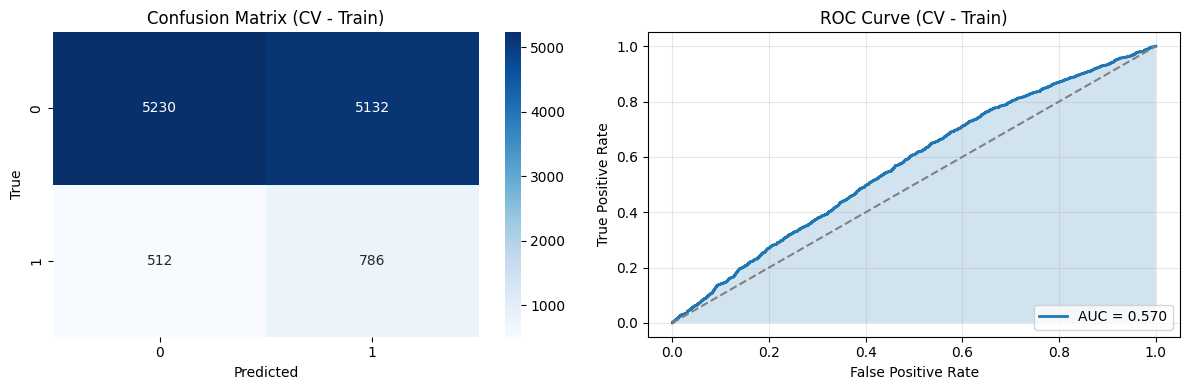

In [32]:
# Visualisation matrice de confusion et courbe ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Matrice de confusion 
cm = confusion_matrix(y_train, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Confusion Matrix (CV - Train)")

# Calcul ROC
fpr, tpr, thresholds = roc_curve(y_train, y_proba)
auc = roc_auc_score(y_train, y_proba)

axes[1].plot(fpr, tpr, linewidth=2,
             label=f"AUC = {auc:.3f}")

axes[1].plot([0,1], [0,1], "--", color="gray")

axes[1].fill_between(fpr, tpr, alpha=0.2)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (CV - Train)")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
print("Max probability (train CV) :", y_proba.max()) # probabilité maximale prédite par le modèle
print("Baseline CV ROC-AUC :", roc_auc_score(y_train, y_proba))

pd.DataFrame({
    "y": y_train,
    "score": y_proba
}).groupby("y").mean()

Max probability (train CV) : 0.6840317576818187
Baseline CV ROC-AUC : 0.5700699768533183


,score
y,
0,0.487663
1,0.502908


Le modele ne vois pas une différence claire entre les patients qui feront une exacerbation et ceux qui n’en feront pas (AUC=0.57). Il distingue à peine mieux que le hasard.

***Distribution des probabilités***

La distribution des probabilités permet d’évaluer visuellement la séparabilité des classes. Le seuil de décision transforme ces probabilités en classes prédictes, et son ajustement contrôle le compromis précision–rappel. Le seuil peut être optimisé en fonction de l’objectif clinique (dépistage sensible ou prédiction plus spécifique).

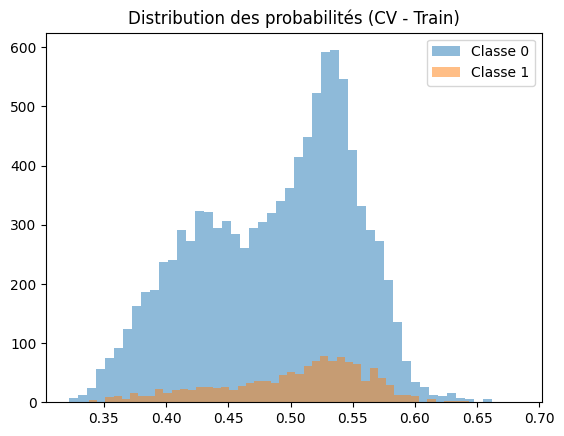

In [34]:
plt.hist(y_proba[y_train==0], bins=50, alpha=0.5, label="Classe 0")
plt.hist(y_proba[y_train==1], bins=50, alpha=0.5, label="Classe 1")
plt.legend()
plt.title("Distribution des probabilités (CV - Train)")
plt.show()

Les 2 distributions se chevaufent fortement , le modeles sépare mal les claees

***Courbe d apprentissage (lEARNING CURVE)***

**Le modèle manque-t-il de données ? Ou manque-t-il d’information ?**

- > Si Train  >> Val  → overfitting , ++données aideraient. Bagging ↓ variance (réduit l’overfitting)
- > Si les deux sont bas et se rejoignent → → Underfitting (biais), le modèle est limité par la structure des données.
- > Si Val monte encore → manque de données

[learning_curve] Training set sizes: [ 932 3031 5130 7229 9328]


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  13 out of  25 | elapsed:    7.9s remaining:    7.3s
[Parallel(n_jobs=-1)]: Done  25 out of  25 | elapsed:   14.4s finished


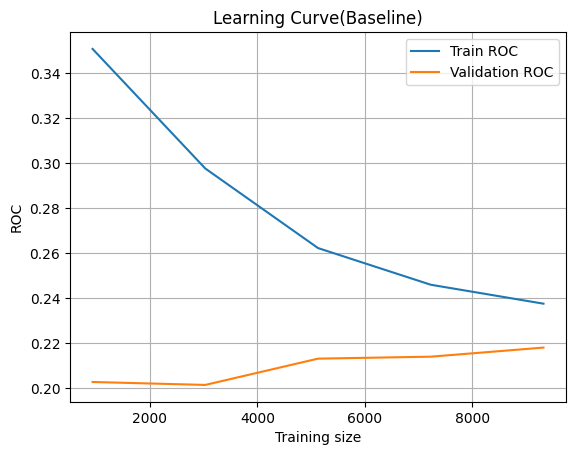

In [35]:
train_sizes, train_scores, val_scores = learning_curve(
    pipe,
    X_train,
    y_train,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=2,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Train ROC")
plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation ROC")
plt.legend()
plt.xlabel("Training size")
plt.ylabel("ROC")
plt.title("Learning Curve(Baseline)")
plt.grid()
plt.show()

Les 2 courbe d apprentissage sont basses , proches et convergent . Le modele n est pas en surapprentissage ,  il y a un biais élévé (underfitting). 

***Hyperparam tuning***

[Validation croisé , optimisation des hyperparametre , seuile de decision , metrics de prediction , courbe de validation ](https://scikit-learn.org/stable/model_selection.html)

Les hyperparamètres sont des paramètres qui ne sont pas directement appris par les estimateurs. Dans scikit-learn, ils sont passés comme arguments au constructeur des classes d'estimateurs

- Pourquoi optimiser les hyperparamètres ? = Impact majeur sur les performances
- Le bon réglage peut gagner 10-15% de performance !

 ***Stratégie de recherche du meilleur hyperparametre***

- Choix un estimateur (régresseur ou classificateur tel que sklearn.svm.SVC());
- Definir un espace de paramètres ;
- Choix d'une méthode de recherche ou d'échantillonnage de candidats ; [Recherche bayesienne](https://www.nextstruggle.com/bayesian-optimization-for-hyperparameter-tuning-in-python-scikit-learn/askdushyant/) 
- un schéma de validation croisée ; et
- une fonction de score .


In [36]:
# Cross-validation stratifiée
# StratifiedKFold : garde la même proportion de classe 1 dans chaque fold.
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42)
# Pour chaque combinaison d’hyperparamètres :
# Il entraîne le modèle sur les folds
# Il évalue sur les folds
# Il calcule la moyenne CV
# Il compare les scores
# Il garde le meilleur


# Espace de recherche

param_space_wide = {
    "model__n_estimators": Integer(100, 500),
    "model__max_samples": Real(0.6, 1.0),

    "model__estimator__max_depth": Integer(3, 20),
    "model__estimator__min_samples_leaf": Integer(2, 20),
}

# model__n_estimators → nombre d’arbres
# model__estimator__max_depth → profondeur des arbres
# model__estimator__min_samples_leaf → régularisation structurelle
# model__max_samples → % d’observations bootstrapées
# model__max_features → % de features utilisées par arbre entier


# Optimisation bayésienne
search = BayesSearchCV(
    estimator=pipe,
    search_spaces=param_space_wide,
    n_iter=80,
    scoring="f1",
    cv=cv,
    refit=True, # apres meilleur hyperparametre trouver, réentraîné sur tout X_train
    n_jobs=-1,
    verbose=0,
    random_state=42
)

search.fit(
    X_train,
    y_train,
    callback=[
        #EarlyStopper(patience=15), # autorise 15 itérations consécutives sans amélioration du score avant d’arrêter l’optimisation.
        DeltaYStopper(delta=0.001) # # Stop si amélioration < 0.005 pendant plusieurs itérations
    ]
)

# Resultat
best_model = search.best_estimator_

print("Best parameters:")
print(search.best_params_)

print("Best CV f1")
print(search.best_score_)



Best parameters:
OrderedDict({'model__estimator__max_depth': 3, 'model__estimator__min_samples_leaf': 11, 'model__max_samples': 0.6471258997869709, 'model__n_estimators': 100})
Best CV f1
0.22303712665057485


***Un arbre individuel dans un bagging***

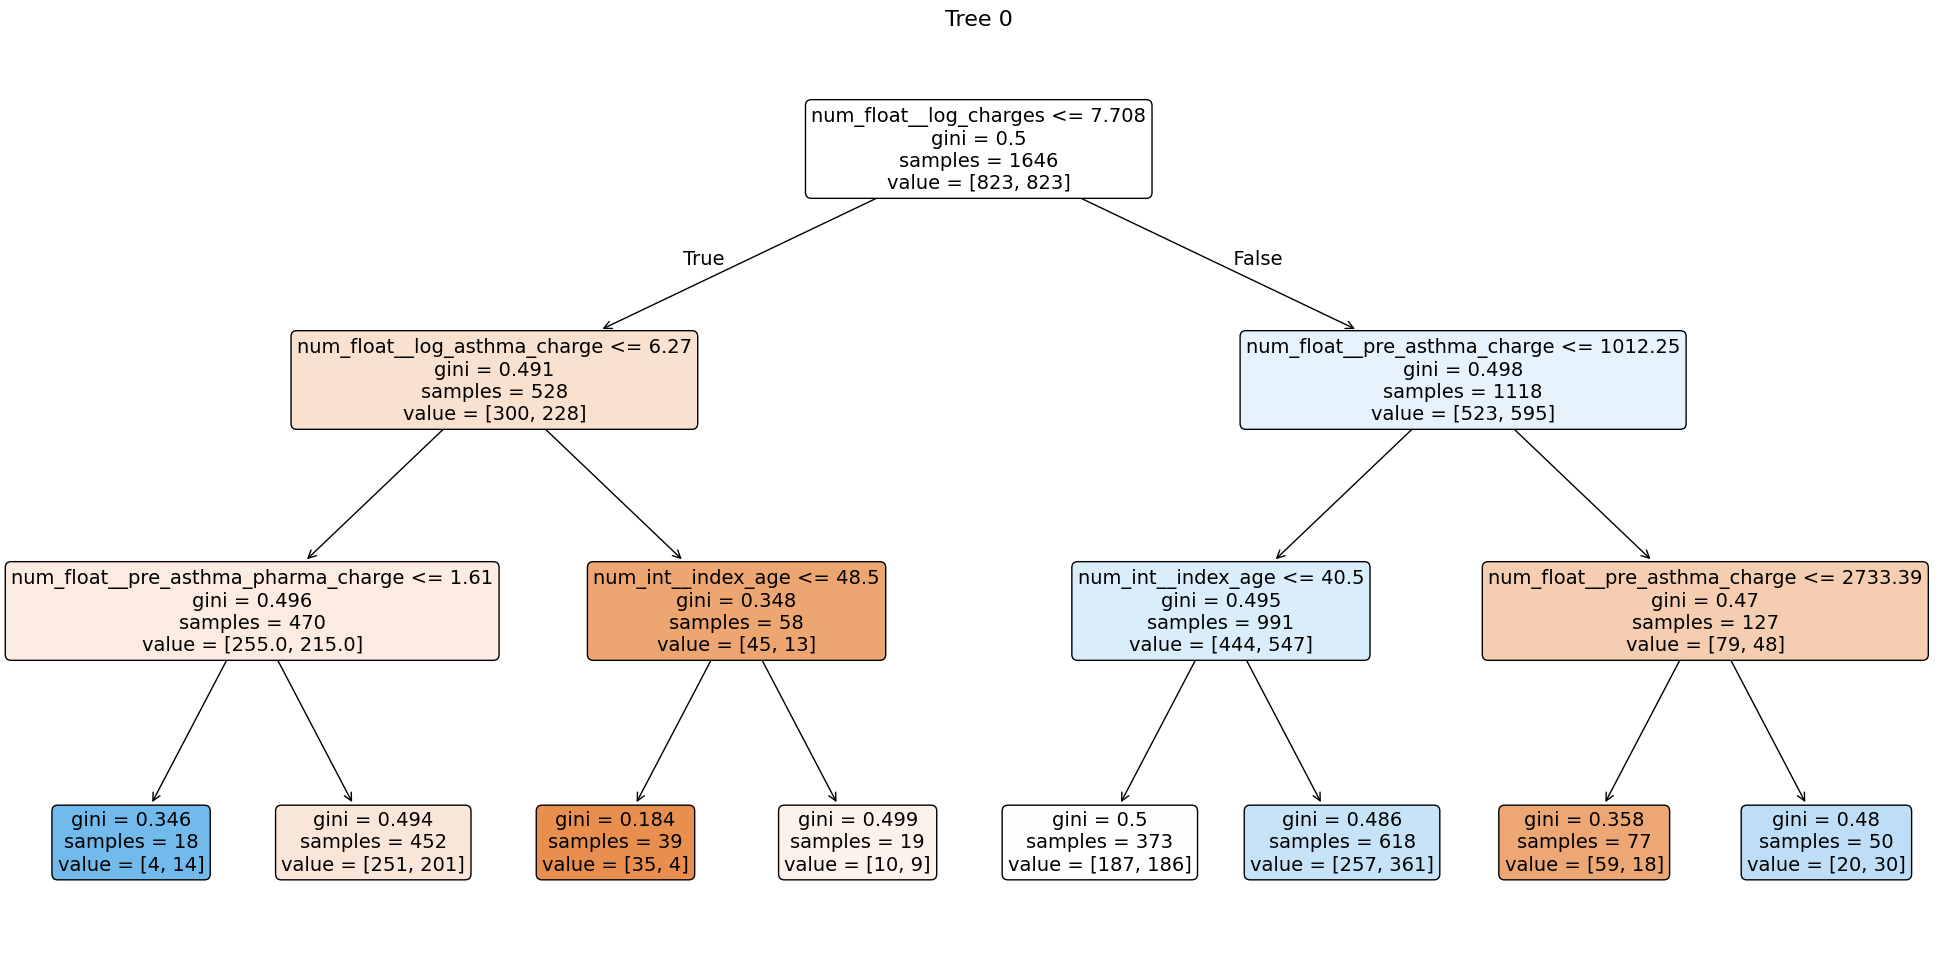

In [37]:
# features 
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
# Avoir acces à un arbre de l estimateur
trees = best_model.named_steps["model"].estimators_

plt.figure(figsize=(25,12))

tree = trees[0].named_steps["classifier"]

plot_tree(
    tree,
    feature_names=feature_names,
    filled=True,
    max_depth=3,
    fontsize=14,
    rounded=True
)

plt.title("Tree 0", fontsize=16)
plt.show()

***Importance des features : Sur qu'elles variables le modele s appuie pour decider ?***

L’indice de Gini est une mesure du degré de mélange des classes dans un nœud d’un arbre de décision.
- Si un nœud contient uniquement une seule classe → Gini = 0 (pur)
- Si les classes sont parfaitement équilibrées → Gini maximal (impur)

À chaque split, l’arbre cherche la variables qui divise les données pour diminuer le Gini le plus possible.

Autrement dit, il cherche à créer des sous-groupes aussi “purs” que possible.

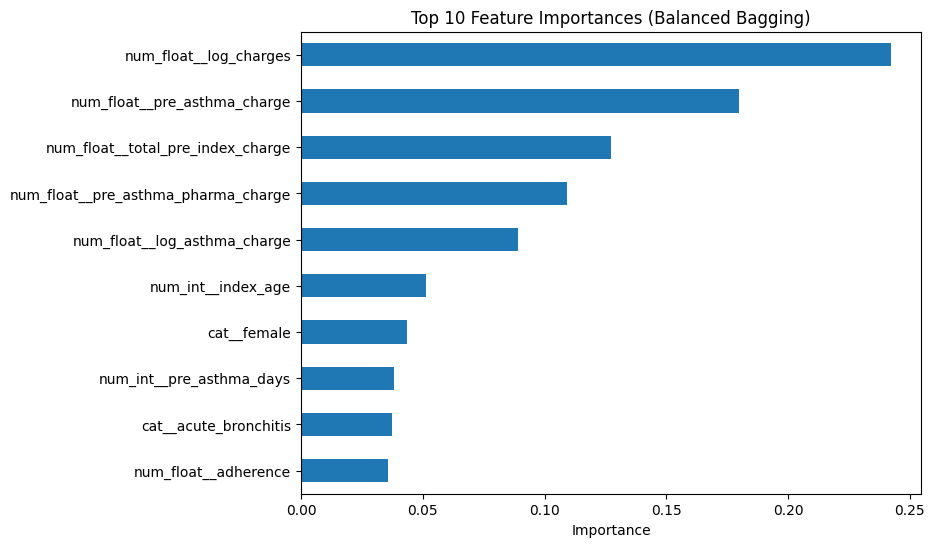

In [38]:
# avoir acces au model 
bagging_model = best_model.named_steps["model"]

n_features = len(feature_names)
all_importances = np.zeros(n_features)

for pipe in bagging_model.estimators_:
    tree = pipe.named_steps["classifier"]
    all_importances += tree.feature_importances_

# Moyenne
all_importances /= len(bagging_model.estimators_)

feat_importances = pd.Series(
    all_importances,
    index=feature_names
)

# Plot
plt.figure(figsize=(8,6))

feat_importances \
    .sort_values(ascending=True) \
    .tail(10) \
    .plot(kind="barh")

plt.title("Top 10 Feature Importances (Balanced Bagging)")
plt.xlabel("Importance")
plt.show()

Dans les arbres du Balanced Bagging, les variables total_pre_index_charge, pre_asthma_pharma_charge et pre_asthma_charge sont les plus utilisées pour effectuer les splits.
Cela signifie que ces variables réduisent le plus souvent l’impureté (Gini) et jouent donc un rôle central dans la discrimination du risque d’exacerbation.

***La permutation importance : mesure de combien la performance (AUC) baisse quand on casse une variable..***

In [39]:
print(best_model.named_steps.keys())

dict_keys(['preprocessor', 'model'])


In [40]:
preprocessor = best_model.named_steps["preprocessor"]
model = best_model.named_steps["model"]

X_transformed = preprocessor.transform(X_train)

result = permutation_importance(
    model,
    X_transformed,
    y_train,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [41]:
perm_df = pl.DataFrame({
    "feature": feature_names,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
})
perm_sorted = perm_df.sort("importance_mean", descending=True)

perm_sorted.head(10)

feature,importance_mean,importance_std
str,f64,f64
"""cat__acute_bronchitis""",0.002564,0.000607
"""cat__female""",0.001252,0.001202
"""num_int__index_age""",0.000823,0.000874
"""cat__rhinitis""",0.000695,0.000486
"""cat__drug_s""",0.000575,0.000328
"""cat__upper_respiratory_infecti…",0.000549,0.0002
"""num_float__pre_asthma_pharma_c…",0.000283,0.002063
"""cat__sinusitis""",0.000266,0.000256
"""num_int__total_pre_index_canni…",0.000214,0.000419


Les importances de permutation sont très faibles et proches entre elles, indiquant qu’aucune variable ne présente un pouvoir discriminant marqué ; le modèle ne repose pas sur un facteur dominant et le signal prédictif reste globalement limité.

***Threshold tuning***

Le threshold est la frontière de décision qui transforme une probabilité continue en classe binaire.

[Seuil (Threshold) compréhension](https://developers.google.com/machine-learning/crash-course/classification/thresholding?hl=fr)

- Le modèle best_model est entraîné en validation croisée sur le train.
- Pour chaque fold, les probabilités sont calculées.
- Le seuil optimal est choisi pour maximiser le F1.
- Ensuite, le modèle est refit automatiquement sur tout le train.
- Le seuil optimal est stocké dans best_threshold_.

In [42]:
threshold_tuner = TunedThresholdClassifierCV(
    estimator=best_model,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
).fit(X_train, y_train)

threshold = threshold_tuner.best_threshold_
print("Best threshold (CV):", threshold_tuner.best_threshold_)
print("Best CV F1 after threshold tuning:", threshold_tuner.best_score_)

Best threshold (CV): 0.4983821614814111
Best CV F1 after threshold tuning: 0.22214667232205168


Confusion matrix:
 [[5246 5116]
 [ 445  853]]


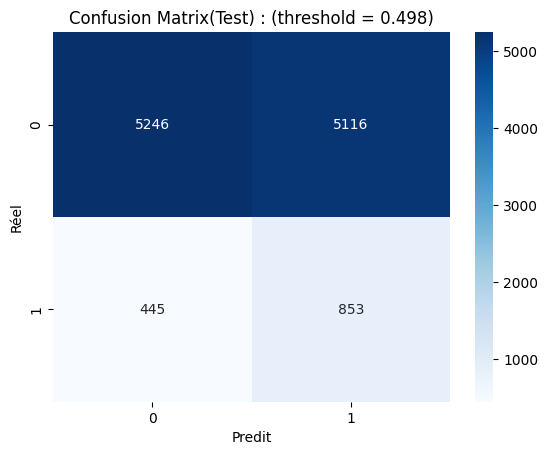

In [43]:
proba_train = threshold_tuner.predict_proba(X_train)[:, 1]
y_pred_train = threshold_tuner.predict(X_train)
# Matrice de confusion (valeurs)
cm = confusion_matrix(y_train, y_pred_train)
print("Confusion matrix:\n", cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predit")
plt.ylabel("Réel")
plt.title(f"Confusion Matrix(Test) : (threshold = {threshold_tuner.best_threshold_:.3f})")
plt.show()


Si on baisses le seuil :
- Plus de patients sont classés “à risque”
- FN ↓
- FP ↑
- Recall ↑
- Precision ↓

Si on augmente le seuil : 
- Moins de patients classés “à risque”
- FN ↑ (on  rates plus de vrais cas)
- FP ↓ (moins de fausses alertes)
- Recall ↓
- Precision ↑

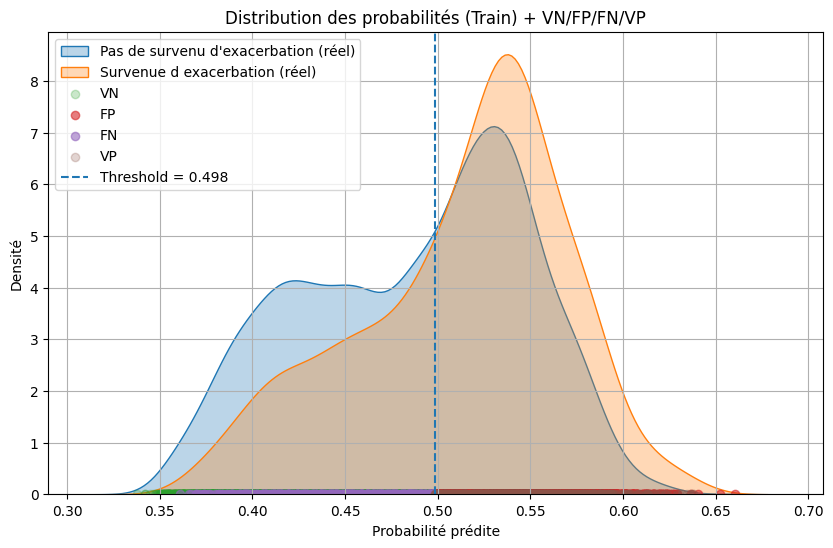

In [44]:
# --- Masques

y_train = y_train.to_numpy()
y_pred_train = np.asarray(y_pred_train)

mask_TN = (y_train == 0) & (y_pred_train == 0)
mask_FP = (y_train == 0) & (y_pred_train == 1)
mask_FN = (y_train == 1) & (y_pred_train == 0)
mask_TP = (y_train == 1) & (y_pred_train == 1)

# --- Plot distribution + points
plt.figure(figsize=(10, 6))

sns.kdeplot(proba_train[y_train == 0],
            label="Pas de survenu d'exacerbation (réel)",
            fill=True, alpha=0.3)

sns.kdeplot(proba_train[y_train == 1],
            label="Survenue d exacerbation (réel)",
            fill=True, alpha=0.3)

plt.scatter(proba_train[mask_TN], np.zeros(np.sum(mask_TN)),
            alpha=0.25, label="VN")
plt.scatter(proba_train[mask_FP], np.zeros(np.sum(mask_FP)),
            alpha=0.6, label="FP")
plt.scatter(proba_train[mask_FN], np.zeros(np.sum(mask_FN)),
            alpha=0.6, label="FN")
plt.scatter(proba_train[mask_TP], np.zeros(np.sum(mask_TP)),
            alpha=0.25, label="VP")

plt.axvline(threshold, linestyle="--", label=f"Threshold = {threshold:.3f}")

plt.xlabel("Probabilité prédite")
plt.ylabel("Densité")
plt.title("Distribution des probabilités (Train) + VN/FP/FN/VP")
plt.legend()
plt.grid(True)
plt.show()

***Évaluation finale sur test set***

In [45]:
y_pred_test = threshold_tuner.predict(X_test)
y_proba_test = threshold_tuner.predict_proba(X_test)[:, 1]
threshold = threshold_tuner.best_threshold_

print("threshold:", threshold)
print("TEST F1:", f1_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test))

threshold: 0.4983821614814111
TEST F1: 0.2364217252396166
              precision    recall  f1-score   support

           0       0.90      0.49      0.64      2551
           1       0.15      0.61      0.24       364

    accuracy                           0.51      2915
   macro avg       0.52      0.55      0.44      2915
weighted avg       0.80      0.51      0.59      2915



- Le seuil bas rend le modèle plus sensible (recall ↑).
- Le modele détecte 61% des vrais cas, il est tres sensible 
- Si la probabilité prédite est supérieure ou égale au seuil, le patient est classé 1 (survenue d’exacerbation).
Sinon classé 0 (pas d’exacerbation).
- Mais il génère beaucoup de faux positifs.

Confusion matrix:
 [[1259 1292]
 [ 142  222]]


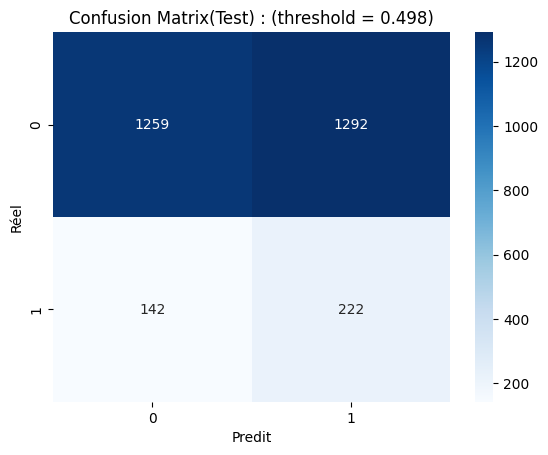

In [46]:
# Matrice de confusion (valeurs)
cm = confusion_matrix(y_test, y_pred_test)
print("Confusion matrix:\n", cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predit")
plt.ylabel("Réel")
plt.title(f"Confusion Matrix(Test) : (threshold = {threshold_tuner.best_threshold_:.3f})")
plt.show()


### --------------------------------------------------------------------------------------------

In [47]:
threshold_tuner

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",StratifiedKFo... shuffle=True)
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary `.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like 

In [ ]:
# Activer affichage diagramme
set_config(display="diagram")

# Générer HTML
html = estimator_html_repr(threshold_tuner)

# Sauvegarder
path = pathlib.Path("pipeline.html")
path.write_text(html, encoding="utf-8")

118181

In [49]:
joblib.dump(threshold_tuner, "final_model.pkl")

['final_model.pkl']

In [50]:
#Charger le model 
model = joblib.load("final_model.pkl")
#Charger le nouveau fichier 
df = pl.read_csv("trainDataDC2.csv.gz")
#Extraire patid
patid = df["patid"]
# Preparer le nouveau fichier
X_new = df.drop("patid")
# Prédiction
prediction = model.predict(X_new)
#Construire resultat
result = pl.DataFrame({
    "patid": patid,
    #"Reel": target,
    "prediction": prediction
})
#Sauvegarder 
result.write_csv("predictions.csv")
print("Fichier predictions.csv généré avec succès.")

Fichier predictions.csv généré avec succès.
